In [ ]:
# run before using other commands     Other Reminder: "cnt" = total number of bike rentals
# We have used the UCI Bike sharing Dataset. We chose this dataset and made the regression model that looks at the data and prepares that data for prediction. Once our data is prepared, the model will predict the total number of bike rentals for each day.
# https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

import pandas as pd                             
import matplotlib.pyplot as plt
import numpy as np

In [3]:
data = pd.read_csv("day.csv")   #reads the day.csv data from file

In [4]:
data.head() #First 5 rows

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
data.info() #shows information about colomns and the data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
data.describe() #gives stats about numerical data

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [7]:
data.shape #shows number of rows and columns

(731, 16)

In [8]:
data.isnull().sum() #counts missing values in colomns

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [9]:
data.columns #shows name of all columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [10]:
data.corr(numeric_only=True)  #checks correlations

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
instant,1.000000,0.412224,0.866025,0.496702,0.016145,-0.000016,-0.004337,-0.021477,0.150580,0.152638,0.016375,-0.112620,0.275255,0.659623,0.628830
season,0.412224,1.000000,-0.001844,0.831440,-0.010537,-0.003080,0.012485,0.019211,0.334315,0.342876,0.205445,-0.229046,0.210399,0.411623,0.406100
yr,0.866025,-0.001844,1.000000,-0.001792,0.007954,-0.005461,-0.002013,-0.048727,0.047604,0.046106,-0.110651,-0.011817,0.248546,0.594248,0.566710
mnth,0.496702,0.831440,-0.001792,1.000000,0.019191,0.009509,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,0.123006,0.293488,0.279977
holiday,0.016145,-0.010537,0.007954,0.019191,1.000000,-0.101960,-0.253023,-0.034627,-0.028556,-0.032507,-0.015937,0.006292,0.054274,-0.108745,-0.068348
weekday,-0.000016,-0.003080,-0.005461,0.009509,-0.101960,1.000000,0.035790,0.031087,-0.000170,-0.007537,-0.052232,0.014282,0.059923,0.057367,0.067443
workingday,-0.004337,0.012485,-0.002013,-0.005901,-0.253023,0.035790,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156
weathersit,-0.021477,0.019211,-0.048727,0.043528,-0.034627,0.031087,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,-0.247353,-0.260388,-0.297391
temp,0.150580,0.334315,0.047604,0.220205,-0.028556,-0.000170,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp,0.152638,0.342876,0.046106,0.227459,-0.032507,-0.007537,0.052182,-0.121583,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066


In [11]:
data.corr(numeric_only=True)["cnt"].sort_values()  #check correlation with only cnt

weathersit   -0.297391
windspeed    -0.234545
hum          -0.100659
holiday      -0.068348
workingday    0.061156
weekday       0.067443
mnth          0.279977
season        0.406100
yr            0.566710
temp          0.627494
instant       0.628830
atemp         0.631066
casual        0.672804
registered    0.945517
cnt           1.000000
Name: cnt, dtype: float64

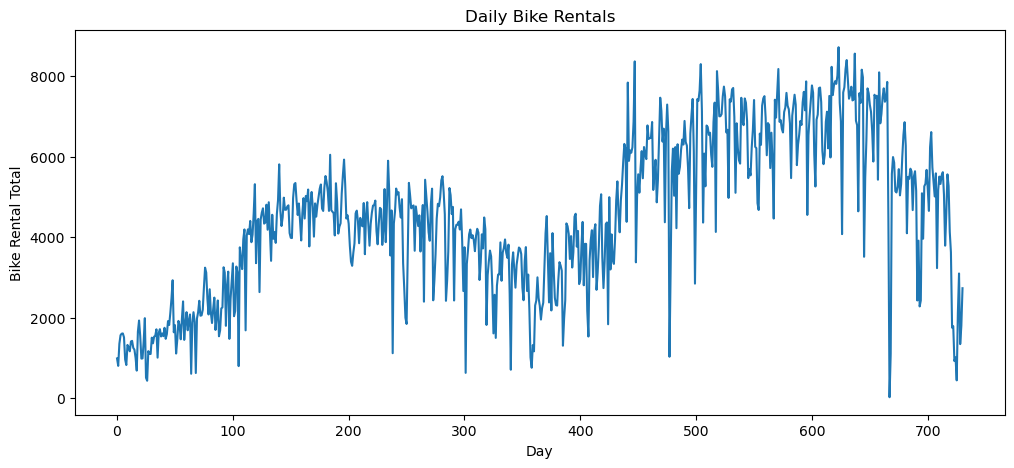

In [12]:
plt.figure(figsize=(12, 5))  #makes the size of figure

plt.plot(data["cnt"])  #plots data from the cnt column

plt.xlabel("Day")  #puts a title name under the x axis of chart

plt.ylabel("Bike Rental Total")  #puts a title name beside the y axis of chart

plt.title ("Daily Bike Rentals")  #main title of chart

plt.show()  #display graph, but shows without it? (Kept in case if needed to know later)

Text(0.5, 1.0, 'Temperature and Bike Rentals')

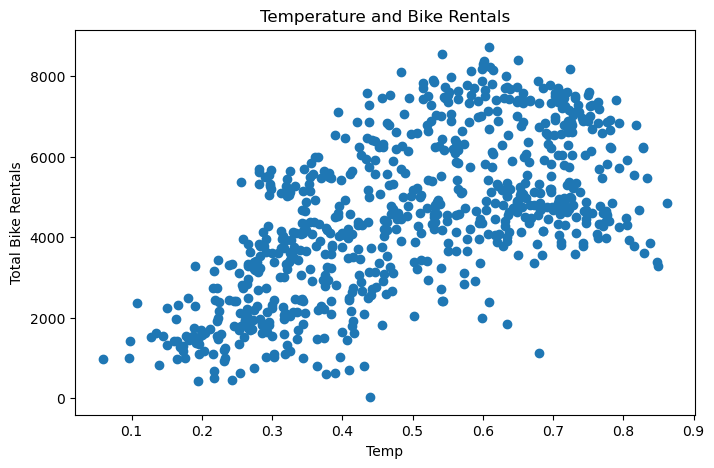

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(data["temp"],data["cnt"])  #makes figure a scatter plot

plt.xlabel("Temp")
plt.ylabel("Total Bike Rentals")
plt.title("Temperature and Bike Rentals")

Text(0.5, 1.0, 'Wind Speed and Bike Rentals')

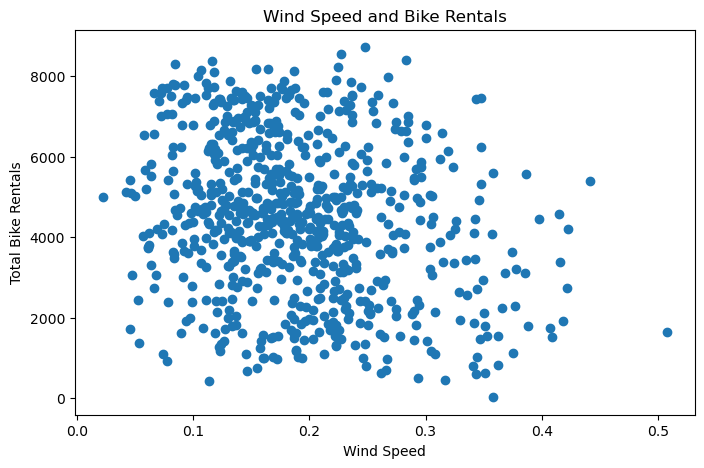

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(data["windspeed"], data["cnt"])

plt.xlabel("Wind Speed")
plt.ylabel("Total Bike Rentals")
plt.title("Wind Speed and Bike Rentals")

In [15]:
features = ["season","yr","mnth","holiday","weekday","workingday","temp","atemp","hum","windspeed"]   #list named features

X = data[features]  #data in features list will equal X
y = data["cnt"]  #cnt column will equal y

In [16]:
X.head()  #shows first five rows

,season,yr,mnth,holiday,weekday,workingday,temp,atemp,hum,windspeed
0,1,0,1,0,6,0,0.344167,0.363625,0.805833,0.160446
1,1,0,1,0,0,0,0.363478,0.353739,0.696087,0.248539
2,1,0,1,0,1,1,0.196364,0.189405,0.437273,0.248309
3,1,0,1,0,2,1,0.200000,0.212122,0.590435,0.160296
4,1,0,1,0,3,1,0.226957,0.229270,0.436957,0.186900


In [17]:
y.head()   #shows first five values

0     985
1     801
2    1349
3    1562
4    1600
Name: cnt, dtype: int64

In [18]:
X.shape  #shows size of data (rows, columns)

(731, 10)

In [19]:
y.shape  #shows number of target values

(731,)

In [20]:
from sklearn.model_selection import train_test_split  #imports train_test_split function/tool from sklearn

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42)   #trains and tests X and y inputs (in that order)

In [29]:
test_size = 0.2   #20%(0.2) of data is for TESTING (80% is TRAINING)

In [30]:
random_state = 42   #random split control

In [31]:
X_train.shape   #how much data is going into training

(584, 10)

In [25]:
X_test.shape   #how much data is going into testing

(147, 10)

In [26]:
y_train.shape   #how many training answers there are

(584,)

In [27]:
y_test.shape   #how many testing answers there are

(147,)

In [33]:
from sklearn.linear_model import LinearRegression

In [35]:
lin_reg = LinearRegression()

In [36]:
lin_reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:
y_pred = lin_reg.predict(X_test)

In [43]:
some_data = X_test.iloc[:5]
some_labels = y_test.iloc[:5]

print ("Predictions:", lin_reg.predict(some_data))
print ("Labels:", some_labels.values)

Predictions: [5798.96297814 1424.9803793  3383.61481047 4644.90029285 6581.6730697 ]
Labels: [6606 1550 3747 6041 7538]


In [46]:
from sklearn.metrics import mean_squared_error

In [48]:
y_pred = lin_reg.predict(X_test)
lin_mse = mean_squared_error(y_test, y_pred)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

np.float64(852.1507476829111)

In [49]:
from sklearn.metrics import mean_absolute_error

lin_mae = mean_absolute_error(y_test, y_pred)
lin_mae

614.9403820046965

In [63]:
def display_scores(scores):
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

In [64]:
lin_scores = cross_val_score(lin_reg,X_train,y_train,scoring="neg_mean_squared_error",cv=10)
lin_rmse_scores = np.sqrt(-lin_scores)
display_scores(lin_rmse_scores)

Scores: [1009.4583705   964.2353487  1098.42319115  620.25144867 1071.44849433
  921.21377802  975.98522396 1138.90385713  830.46142266  757.9445892 ]
Mean: 938.8325724311704
Standard deviation: 153.742451557911


In [68]:
final_predictions = lin_reg.predict(X_test)

final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)
final_mae = mean_absolute_error(y_test, final_predictions)

print("Final RMSE:", final_rmse)
print("Final MAE:", final_mae)

Final RMSE: 852.1507476829111
Final MAE: 614.9403820046965


In [69]:
final_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": final_predictions
})

print(final_results.head(10))

     Actual    Predicted
703    6606  5798.962978
33     1550  1424.980379
300    3747  3383.614810
456    6041  4644.900293
633    7538  6581.673070
557    7264  7034.549801
39     1605  1239.439734
356    2209  1699.741078
559    7499  7835.453326
514    5743  6084.265878
